# Punto 1 – Clustering con K-Means sobre un dataset aleatorio


- Número de centroides entre **1 y 20**.
- Posiciones aleatorias, garantizando una **distancia mínima grande** entre ellos (para poder verificar visualmente el resultado).
- Dispersión (distancia de los puntos al centroide) aleatoria por grupo.
- Número de puntos aleatorio por grupo.

Después se aplica **K-Means** y se grafica: centroides finales, número de puntos por centroide y los **5 puntos más cercanos** a cada centroide.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

plt.rcParams["figure.dpi"] = 110

## 1. Generador de dataset aleatorio

**Idea clave para la separación visual:** la desviación estándar máxima de un grupo es `STD_MAX`. Si la distancia mínima entre centroides es `MIN_DIST = 8 * STD_MAX`, los grupos casi no se solapan (≈ 4 desviaciones de cada lado). Las posiciones se sortean con *rejection sampling*: se propone un punto al azar y solo se acepta si queda a más de `MIN_DIST` de todos los centroides ya aceptados. Si no cabe, se agranda el área de sorteo.

In [5]:
STD_MIN, STD_MAX = 0.4, 1.0          # rango de dispersión de cada grupo
MIN_DIST = 8 * STD_MAX              # distancia mínima entre centroides
PTS_MIN, PTS_MAX = 40, 300          # rango de puntos por centroide


def generar_centroides(k, rng, min_dist=MIN_DIST):
    """Posiciones aleatorias de k centroides separados al menos `min_dist`."""
    lado = min_dist * np.sqrt(k) * 1.5          # tamaño inicial del área de sorteo
    centroides = []
    intentos = 0
    while len(centroides) < k:
        candidato = rng.uniform(-lado, lado, size=2)
        if all(np.linalg.norm(candidato - c) >= min_dist for c in centroides):
            centroides.append(candidato)
            intentos = 0
        else:
            intentos += 1
            if intentos > 500:                  # no cabe: agrandar el área
                lado *= 1.2
                intentos = 0
    return np.array(centroides)


def generar_dataset(seed=None):
    """Dataset 2D con k aleatorio (1-20), posiciones, dispersiones y tamaños aleatorios."""
    rng = np.random.default_rng(seed)
    k = int(rng.integers(1, 21))                          # entre 1 y 20
    centroides = generar_centroides(k, rng)               # posiciones aleatorias
    stds = rng.uniform(STD_MIN, STD_MAX, size=k)          # distancia de los puntos al centroide
    tamanos = rng.integers(PTS_MIN, PTS_MAX + 1, size=k)  # nº de puntos por centroide

    X, y = [], []
    for i in range(k):
        puntos = rng.normal(loc=centroides[i], scale=stds[i], size=(tamanos[i], 2))
        X.append(puntos)
        y.append(np.full(tamanos[i], i))
    return np.vstack(X), np.concatenate(y), centroides, stds, tamanos


SEED = 7   # pon un número (ej. 7) para repetir siempre el mismo dataset
X, y_real, centroides_reales, stds, tamanos = generar_dataset(SEED)

k = len(centroides_reales)
print(f"Centroides generados: {k}")
print(f"Total de puntos: {len(X)}")
print(f"Puntos por centroide: {tamanos.tolist()}")

Centroides generados: 19
Total de puntos: 2925
Puntos por centroide: [203, 53, 145, 255, 65, 145, 292, 288, 96, 41, 215, 43, 118, 169, 268, 64, 212, 179, 74]


## 2. Dataset generado (con los centroides reales)

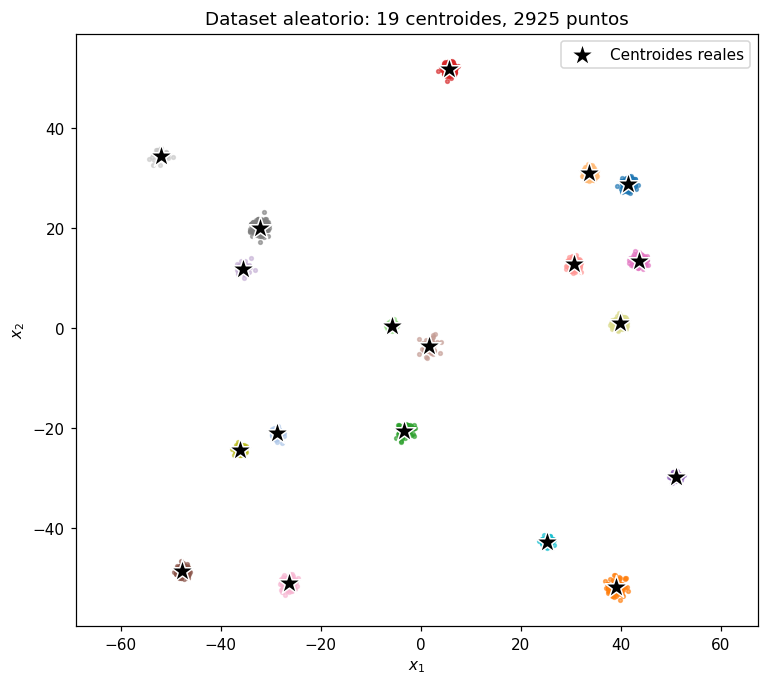

In [10]:
cmap = plt.get_cmap("tab20")
colores = [cmap(i % 20) for i in range(k)]

plt.figure(figsize=(8, 7))
for i in range(k):
    plt.scatter(*X[y_real == i].T, s=6, color=colores[i], alpha=0.6)
plt.scatter(*centroides_reales.T, marker="*", s=250, c="k", edgecolors="w",
            label="Centroides reales", zorder=5)
plt.title(f"Dataset aleatorio: {k} centroides, {len(X)} puntos")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.axis("equal")
plt.legend(); plt.show()

In [11]:
print(y_real)

[ 0  0  0 ... 18 18 18]


## 3. Aplicar K-Means

Como queremos **verificar visualmente** el resultado, usamos `n_clusters = k` (el número real de centroides) y `n_init=10` para reducir el efecto de una mala inicialización.

In [12]:
kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
y_pred = kmeans.fit_predict(X)
centroides_kmeans = kmeans.cluster_centers_

puntos_por_cluster = np.bincount(y_pred, minlength=k)
print("Puntos por cluster (K-Means):", puntos_por_cluster.tolist())

Puntos por cluster (K-Means): [292, 169, 179, 268, 145, 255, 145, 212, 215, 288, 96, 65, 64, 74, 118, 203, 43, 41, 53]


## 4. Los 5 puntos más cercanos a cada centroide

Para cada cluster se calcula la distancia euclídea de sus puntos al centroide y se toman los 5 menores.

In [13]:
def cinco_mas_cercanos(X, y_pred, centroides, n=5):
    resultado = {}
    for i, c in enumerate(centroides):
        idx_cluster = np.where(y_pred == i)[0]
        dist = np.linalg.norm(X[idx_cluster] - c, axis=1)
        orden = np.argsort(dist)[:n]
        resultado[i] = (idx_cluster[orden], dist[orden])
    return resultado

cercanos = cinco_mas_cercanos(X, y_pred, centroides_kmeans)

print(f"{'Cluster':>8} {'Nº puntos':>10}   Distancias de los 5 más cercanos")
for i in range(k):
    d = ", ".join(f"{v:.3f}" for v in cercanos[i][1])
    print(f"{i:>8} {puntos_por_cluster[i]:>10}   {d}")

 Cluster  Nº puntos   Distancias de los 5 más cercanos
       0        292   0.032, 0.070, 0.073, 0.073, 0.098
       1        169   0.067, 0.085, 0.105, 0.120, 0.153
       2        179   0.032, 0.111, 0.112, 0.154, 0.170
       3        268   0.128, 0.134, 0.153, 0.183, 0.201
       4        145   0.081, 0.142, 0.178, 0.182, 0.247
       5        255   0.092, 0.098, 0.099, 0.109, 0.122
       6        145   0.026, 0.055, 0.072, 0.091, 0.113
       7        212   0.053, 0.056, 0.090, 0.093, 0.101
       8        215   0.055, 0.061, 0.073, 0.089, 0.104
       9        288   0.051, 0.053, 0.068, 0.076, 0.089
      10         96   0.063, 0.071, 0.106, 0.138, 0.164
      11         65   0.206, 0.218, 0.240, 0.241, 0.295
      12         64   0.076, 0.121, 0.209, 0.251, 0.280
      13         74   0.079, 0.107, 0.136, 0.162, 0.173
      14        118   0.097, 0.255, 0.290, 0.305, 0.320
      15        203   0.091, 0.096, 0.103, 0.141, 0.148
      16         43   0.089, 0.336, 0.511, 0.554,

## 5. Visualización del proceso completo

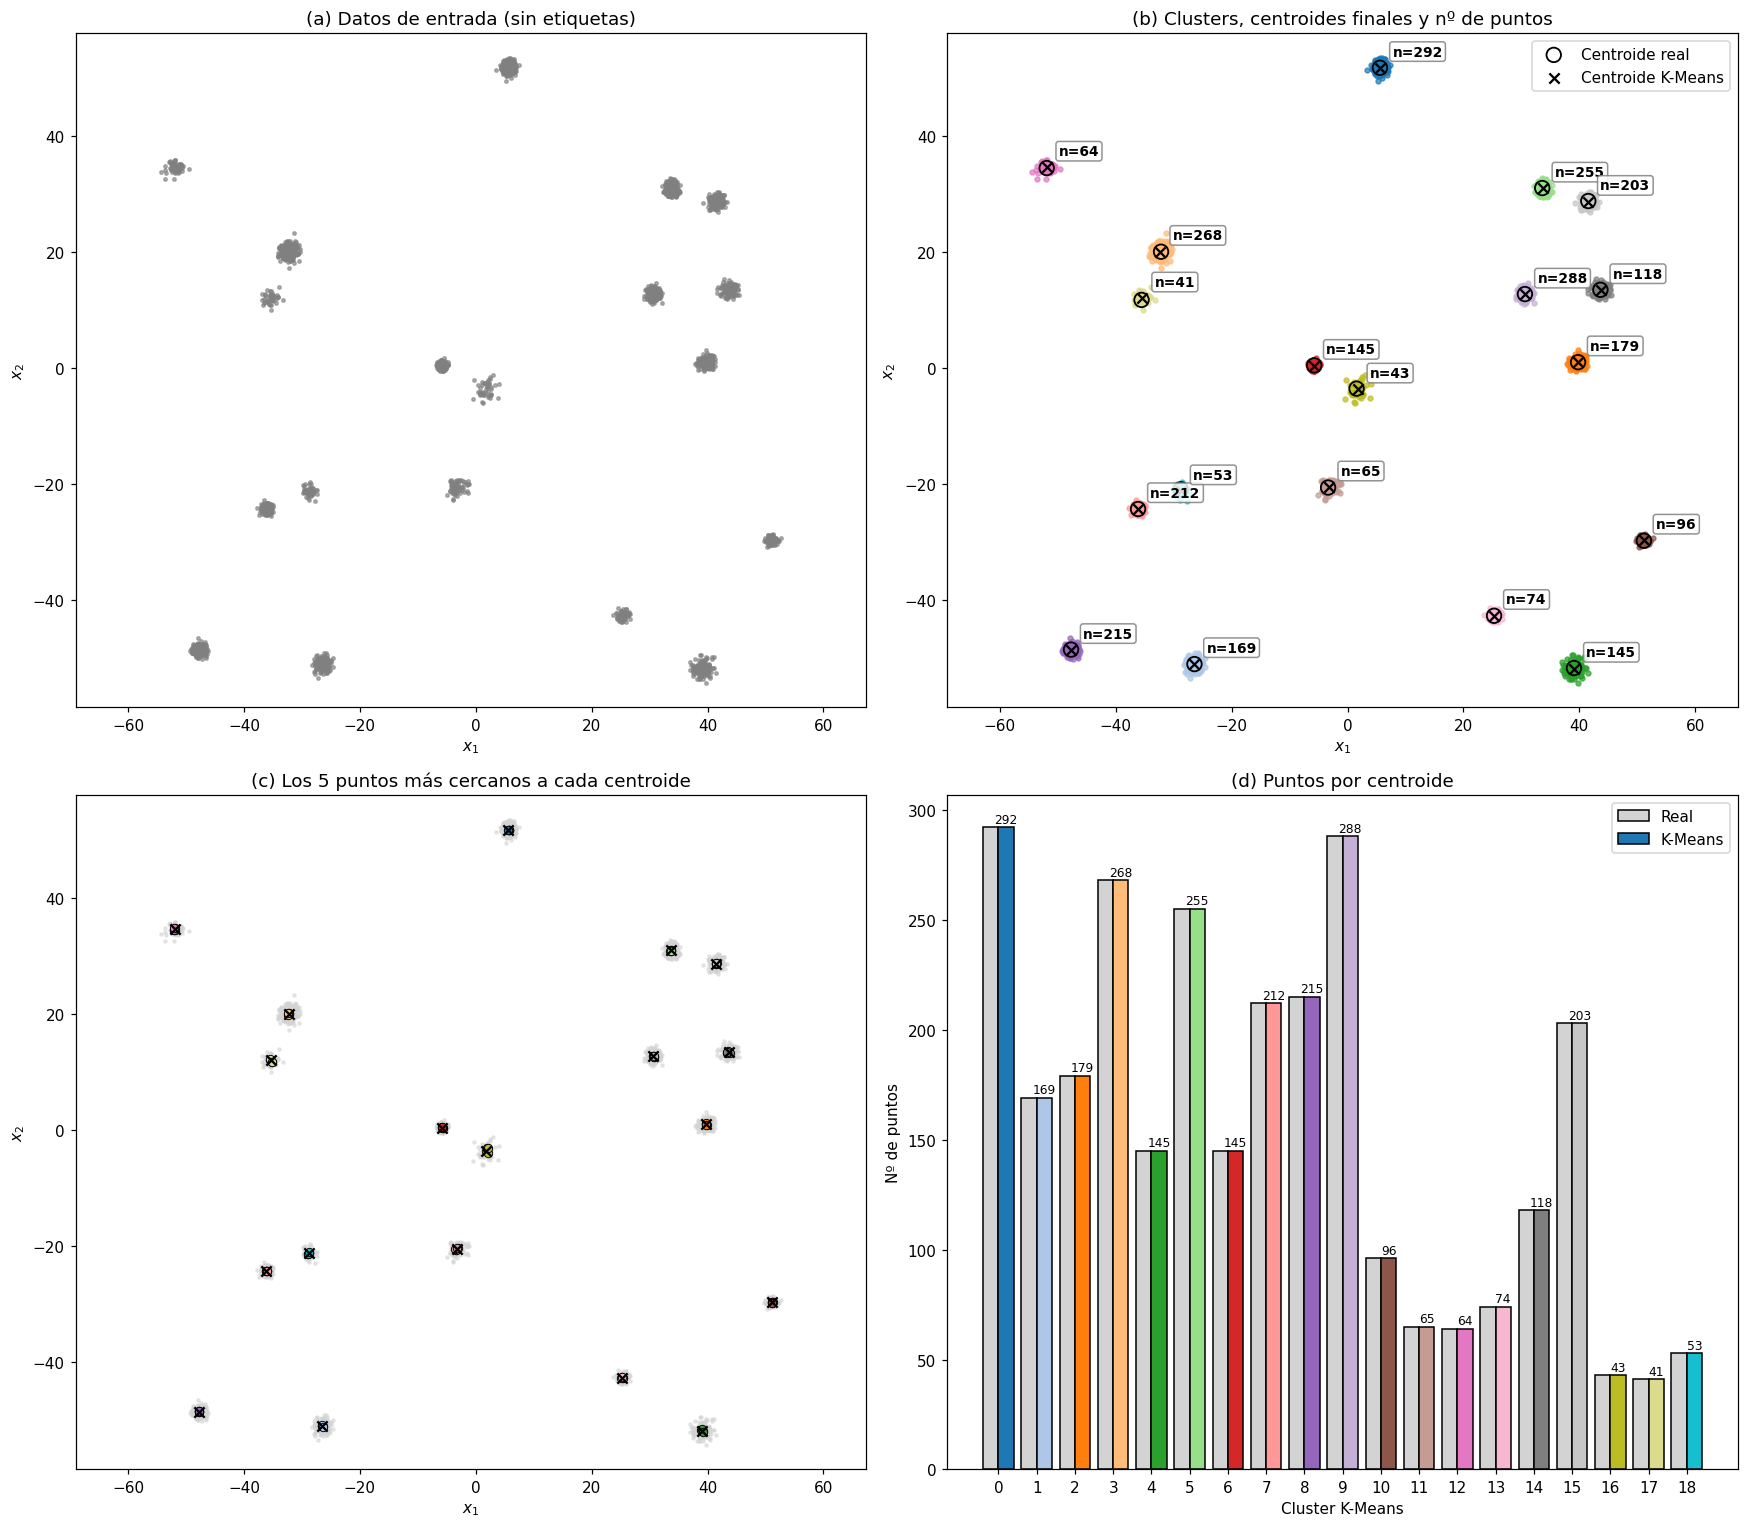

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
ax1, ax2, ax3, ax4 = axes.ravel()

# (a) Datos sin etiquetar: lo que "ve" K-Means
ax1.scatter(*X.T, s=5, color="gray", alpha=0.6)
ax1.set_title("(a) Datos de entrada (sin etiquetas)")

# (b) Resultado: clusters + centroides finales + nº de puntos
for i in range(k):
    ax2.scatter(*X[y_pred == i].T, s=10, color=colores[i], alpha=0.7)
ax2.scatter(*centroides_reales.T, marker="o", s=90, facecolors="none",
            edgecolors="k", linewidths=1.2, label="Centroide real", zorder=4)
ax2.scatter(*centroides_kmeans.T, marker="x", s=45, c="k", linewidths=1.5,
            label="Centroide K-Means", zorder=5)
for i, (cx, cy) in enumerate(centroides_kmeans):
    ax2.annotate(f"n={puntos_por_cluster[i]}", (cx, cy), xytext=(8, 8),
                 textcoords="offset points", fontsize=9, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.2", fc="w", ec="gray", alpha=0.85),
                 zorder=6)
ax2.set_title("(b) Clusters, centroides finales y nº de puntos")
ax2.legend(loc="best")

# (c) 5 puntos más cercanos a cada centroide
ax3.scatter(*X.T, s=4, color="lightgray", alpha=0.5)
for i in range(k):
    idx, _ = cercanos[i]
    ax3.scatter(*X[idx].T, s=30, color=colores[i], edgecolors="k", linewidths=0.6, zorder=4)
    for p in X[idx]:
        ax3.plot([centroides_kmeans[i][0], p[0]], [centroides_kmeans[i][1], p[1]],
                 color=colores[i], lw=1, zorder=3)
ax3.scatter(*centroides_kmeans.T, marker="x", s=45, c="k", linewidths=1.5, zorder=5)
ax3.set_title("(c) Los 5 puntos más cercanos a cada centroide")

# (d) Nº de puntos por centroide: real vs K-Means
# (se empareja cada centroide K-Means con el real más cercano)
dist_cc = np.linalg.norm(centroides_kmeans[:, None] - centroides_reales[None], axis=2)
emparejado = dist_cc.argmin(axis=1)
x = np.arange(k)
ax4.bar(x - 0.2, tamanos[emparejado], width=0.4, color="lightgray",
        edgecolor="k", label="Real")
ax4.bar(x + 0.2, puntos_por_cluster, width=0.4,
        color=[colores[i] for i in range(k)], edgecolor="k", label="K-Means")
for xi, v in zip(x, puntos_por_cluster):
    ax4.text(xi + 0.2, v + 2, str(v), ha="center", fontsize=8)
ax4.set_xticks(x); ax4.set_xlabel("Cluster K-Means")
ax4.set_ylabel("Nº de puntos")
ax4.set_title("(d) Puntos por centroide")
ax4.legend()

for ax in (ax1, ax2, ax3):
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal", "datalim")

plt.tight_layout(); plt.show()

## 5b. Zoom por cluster (los 5 puntos más cercanos)

Con muchos centroides los grupos se ven muy pequeños en el gráfico general, así que aquí se hace un zoom a cada cluster: puntos del grupo en color, los 5 más cercanos resaltados y numerados por orden de cercanía.

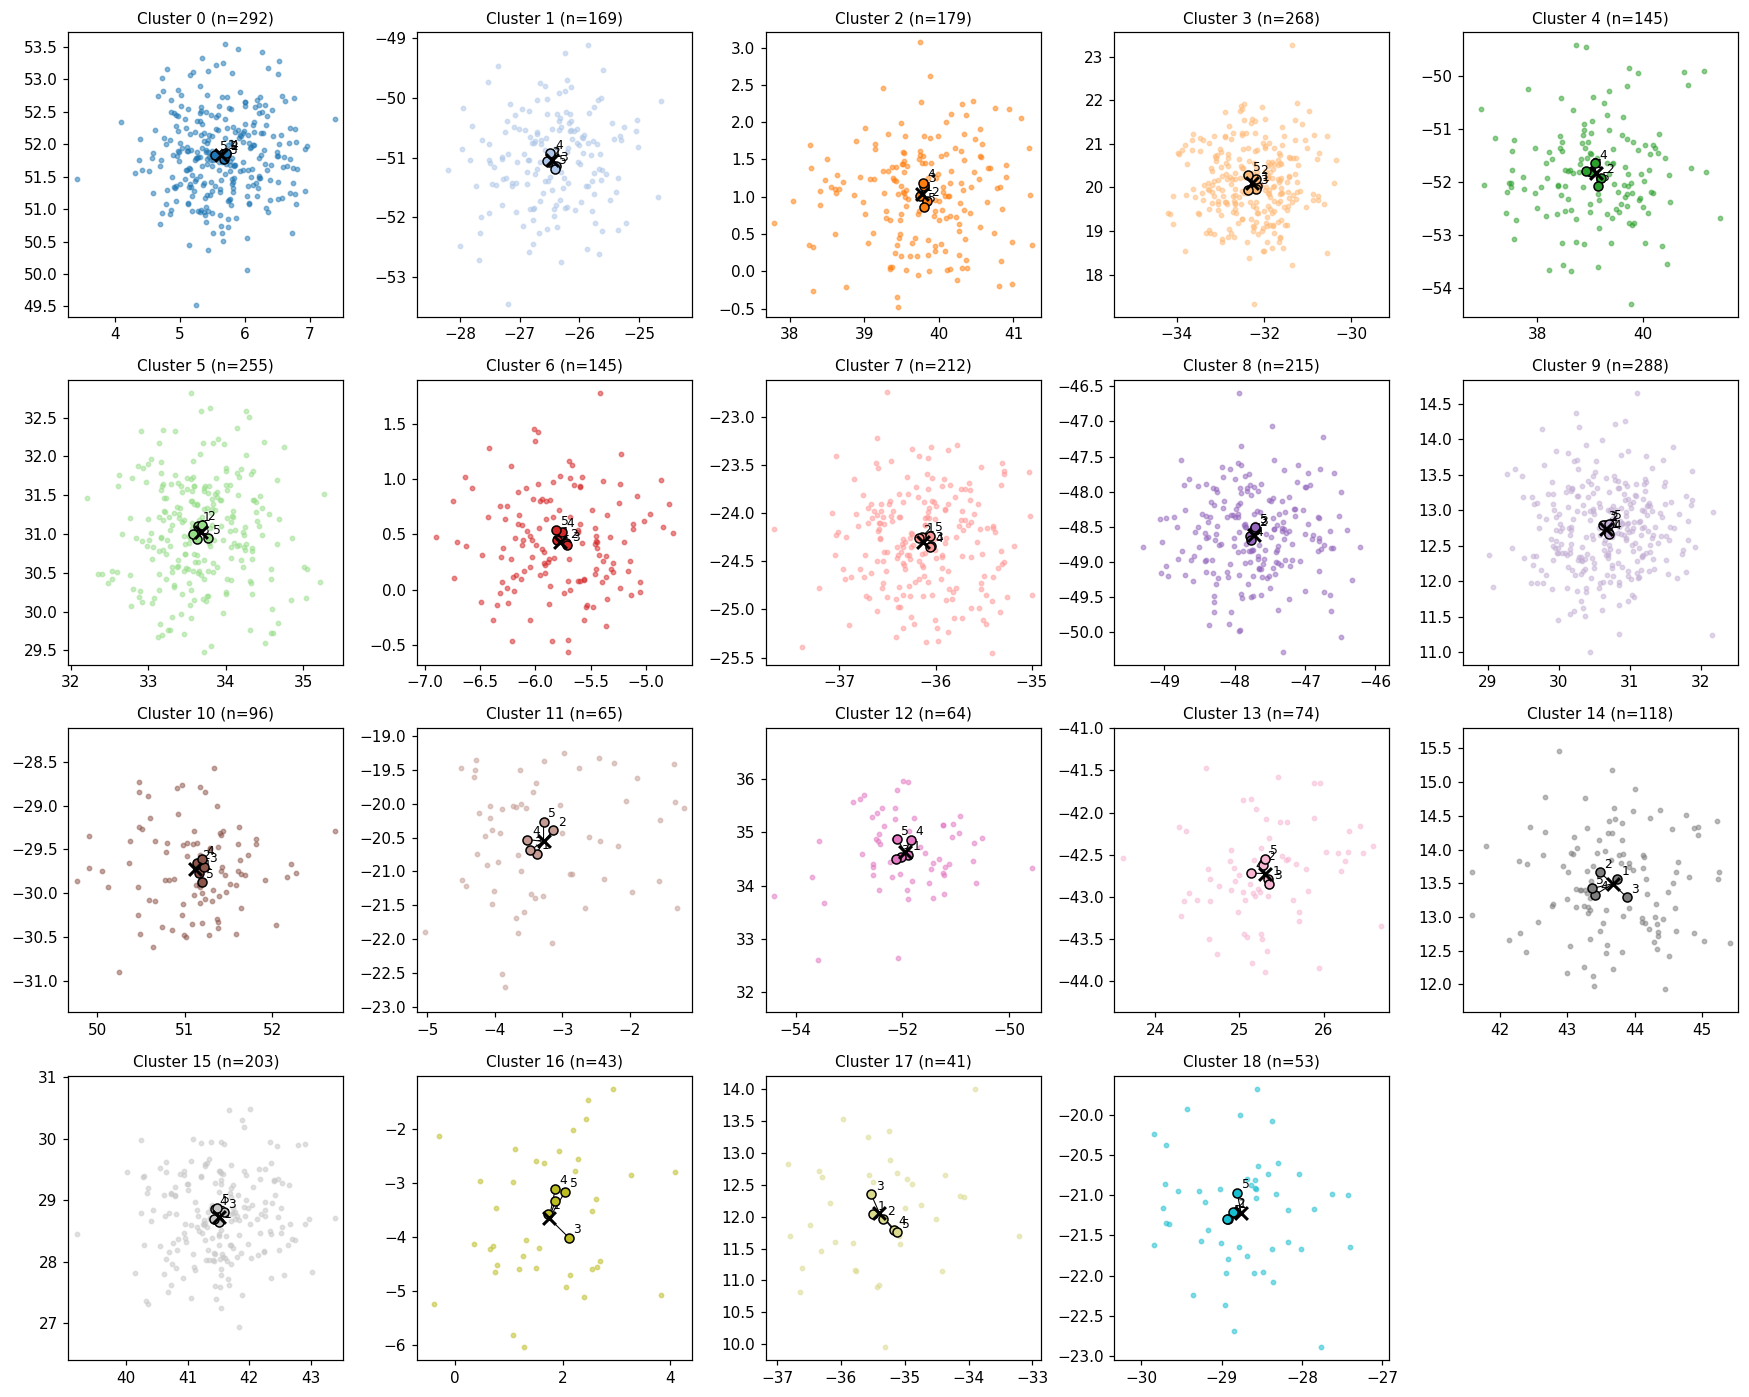

In [15]:
cols = min(5, k)
filas = int(np.ceil(k / cols))
fig, axes = plt.subplots(filas, cols, figsize=(3.2 * cols, 3.2 * filas), squeeze=False)

for i, ax in enumerate(axes.ravel()):
    if i >= k:
        ax.axis("off")
        continue
    pts = X[y_pred == i]
    idx, dist = cercanos[i]
    c = centroides_kmeans[i]
    ax.scatter(*pts.T, s=8, color=colores[i], alpha=0.5)
    ax.scatter(*X[idx].T, s=35, color=colores[i], edgecolors="k", zorder=4)
    for j, p in enumerate(X[idx], start=1):
        ax.plot([c[0], p[0]], [c[1], p[1]], color="k", lw=0.7, zorder=3)
        ax.annotate(str(j), p, xytext=(3, 3), textcoords="offset points", fontsize=8)
    ax.scatter(*c, marker="x", s=70, c="k", linewidths=2, zorder=5)
    ax.set_title(f"Cluster {i} (n={puntos_por_cluster[i]})", fontsize=10)
    ax.set_aspect("equal", "datalim")

plt.tight_layout(); plt.show()

## 6. Verificación numérica

Distancia entre cada centroide real y el centroide que encontró K-Means (si es cercana a 0, K-Means recuperó bien el grupo).

In [16]:
error_centroides = dist_cc.min(axis=1)
print(f"Error medio de los centroides: {error_centroides.mean():.3f}")
print(f"Error máximo de los centroides: {error_centroides.max():.3f}")
print("¿Cada centroide real fue asignado a un solo cluster?",
      len(set(emparejado)) == k)

Error medio de los centroides: 0.098
Error máximo de los centroides: 0.319
¿Cada centroide real fue asignado a un solo cluster? True


## Conclusiones

- Al forzar una distancia mínima de `8 × STD_MAX` entre centroides, los grupos quedan visualmente separados y K-Means los recupera con muy poco error.
- Si se ejecuta varias veces (cambiando `SEED`) con valores altos de `k`, a veces K-Means puede fusionar o dividir grupos aunque estén lejanos: es el problema de la **inicialización** visto en el cuaderno original. `n_init=10` y `k-means++` lo reducen.
- En un caso real (sin etiquetas) no conoceríamos `k`; se estimaría con el *silhouette score*.